# Window Functions for Analytics

`GROUP BY` collapses rows into one row per group. **Window functions** compute a value **across related rows but keep every row**: a running total, a rank within a group, the value of the previous month. They are the most important SQL feature for analytics.

**After this lesson you can:**

1. Write `function() OVER (PARTITION BY ... ORDER BY ...)`.
2. Compute running totals and moving averages with frames.
3. Rank rows with `ROW_NUMBER`, `RANK`, `DENSE_RANK` and `NTILE`.
4. Compare rows with `LAG` and `LEAD`, and compute growth rates.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. The `OVER` Clause

```sql
aggregate_or_window_function(...) OVER (
    PARTITION BY group_columns      -- restart the calculation for each group
    ORDER BY sort_columns           -- order inside the group
    ROWS BETWEEN ... AND ...        -- the frame: which rows around the current row
)
```

The example adds the country total and the share to every invoice, without collapsing the rows.

In [2]:
q("""
SELECT invoice_id, billing_country, total,
       sum(total) OVER (PARTITION BY billing_country) AS country_total,
       round(100 * total / sum(total) OVER (PARTITION BY billing_country), 1) AS pct_of_country
FROM invoice
WHERE billing_country IN ('Germany', 'Norway')
ORDER BY billing_country, invoice_id
LIMIT 8
""")

,invoice_id,billing_country,total,country_total,pct_of_country
0,1,Germany,1.98,156.48,1.3
1,6,Germany,0.99,156.48,0.6
2,7,Germany,1.98,156.48,1.3
3,12,Germany,13.86,156.48,8.9
4,29,Germany,1.98,156.48,1.3
5,30,Germany,3.96,156.48,2.5
6,40,Germany,13.86,156.48,8.9
7,52,Germany,5.94,156.48,3.8


## 2. Running Totals and Moving Averages

With `ORDER BY` inside `OVER`, the default frame is "from the first row to the current row", which gives a **running total**. `ROWS BETWEEN 2 PRECEDING AND CURRENT ROW` gives a 3-row **moving window**.

In [3]:
monthly = q("""
WITH m AS (
    SELECT date_trunc('month', invoice_date)::date AS month, sum(total) AS revenue
    FROM invoice GROUP BY 1
)
SELECT month, revenue,
       sum(revenue) OVER (ORDER BY month) AS running_total,
       avg(revenue) OVER (ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS moving_avg_3m,
       revenue - lag(revenue) OVER (ORDER BY month) AS change_vs_prev
FROM m ORDER BY month
""")
monthly.head(6)

,month,revenue,running_total,moving_avg_3m,change_vs_prev
0,2021-01-01,35.64,35.64,35.64,NaN
1,2021-02-01,37.62,73.26,36.63,1.98
2,2021-03-01,37.62,110.88,36.96,0.00
3,2021-04-01,37.62,148.50,37.62,0.00
4,2021-05-01,37.62,186.12,37.62,0.00
5,2021-06-01,37.62,223.74,37.62,0.00


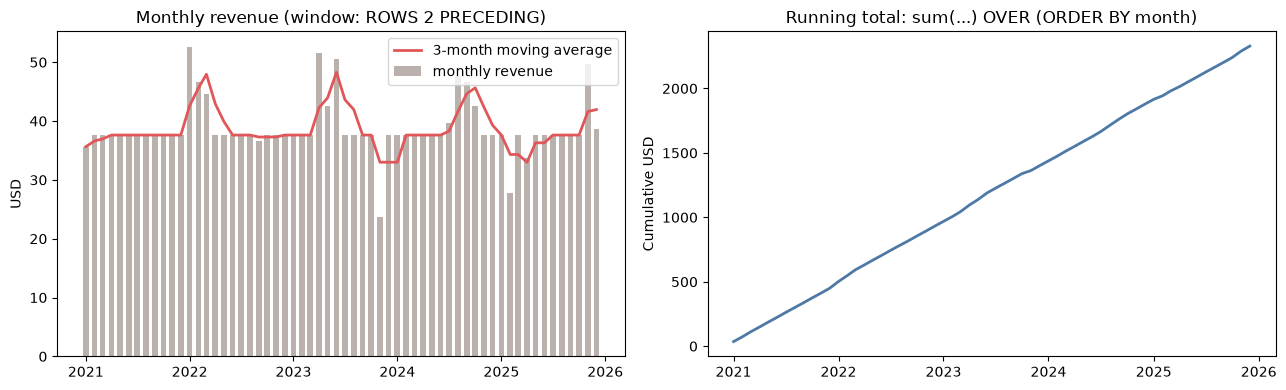

In [4]:
m = monthly.astype({"revenue": float, "running_total": float, "moving_avg_3m": float})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(m["month"], m["revenue"], width=20, color="#BAB0AC", label="monthly revenue")
ax1.plot(m["month"], m["moving_avg_3m"], color="#E15759", lw=2, label="3-month moving average")
ax1.set(title="Monthly revenue (window: ROWS 2 PRECEDING)", ylabel="USD")
ax1.legend()
ax2.plot(m["month"], m["running_total"], color="#4E79A7", lw=2)
ax2.set(title="Running total: sum(...) OVER (ORDER BY month)", ylabel="Cumulative USD")
plt.tight_layout()
plt.show()

## 3. Ranking

| Function | Ties | Example values for scores 10, 9, 9, 8 |
| :--- | :--- | :--- |
| `ROW_NUMBER()` | unique numbers, ties broken arbitrarily | 1, 2, 3, 4 |
| `RANK()` | same rank, then a gap | 1, 2, 2, 4 |
| `DENSE_RANK()` | same rank, no gap | 1, 2, 2, 3 |
| `NTILE(n)` | splits rows into *n* buckets | quartiles, deciles |

A classic pattern is **top-N per group**: rank inside each group, then keep `rank <= N`.

In [5]:
top_artists = q("""
WITH artist_country AS (
    SELECT i.billing_country AS country, ar.name AS artist, sum(il.unit_price * il.quantity) AS revenue
    FROM invoice_line il
    JOIN invoice i ON i.invoice_id = il.invoice_id
    JOIN track t ON t.track_id = il.track_id
    JOIN album al ON al.album_id = t.album_id
    JOIN artist ar ON ar.artist_id = al.artist_id
    GROUP BY 1, 2
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY country ORDER BY revenue DESC) AS rnk,
              ROW_NUMBER() OVER (PARTITION BY country ORDER BY revenue DESC, artist) AS rn
    FROM artist_country
)
SELECT country, rn, rnk, artist, revenue FROM ranked
WHERE rn <= 2 AND country IN ('USA', 'Canada', 'Brazil', 'France')
ORDER BY country, rn
""")
top_artists

,country,rn,rnk,artist,revenue
0,Brazil,1,1,Os Paralamas Do Sucesso,10.89
1,Brazil,2,1,Pearl Jam,10.89
2,Canada,1,1,Os Paralamas Do Sucesso,15.84
3,Canada,2,2,Metallica,14.85
4,France,1,1,Creedence Clearwater Revival,10.89
5,France,2,2,Led Zeppelin,9.90
6,USA,1,1,The Office,33.83
7,USA,2,2,Iron Maiden,33.66


In [6]:
quartiles = q("""
WITH spend AS (SELECT customer_id, sum(total) AS spend FROM invoice GROUP BY customer_id)
SELECT NTILE(4) OVER (ORDER BY spend) AS quartile, count(*) AS customers,
       min(spend) AS min_spend, max(spend) AS max_spend
FROM spend GROUP BY customer_id, spend
""")
quartiles = quartiles.groupby("quartile").agg(customers=("customers", "sum"), min_spend=("min_spend", "min"),
                                               max_spend=("max_spend", "max")).reset_index()
quartiles

,quartile,customers,min_spend,max_spend
0,1,15,36.64,37.62
1,2,15,37.62,37.62
2,3,15,37.62,39.62
3,4,14,40.62,49.62


## 4. `LAG`, `LEAD` and Growth Rates

`LAG(x, k)` returns the value of `x` *k* rows **before** the current row; `LEAD` looks ahead. They compute period-over-period changes, time between events and churn signals. The query computes the gap between consecutive purchases of each customer.

 year  revenue  yoy_growth_pct
 2021   449.46             NaN
 2022   481.45             7.1
 2023   469.58            -2.5
 2024   477.53             1.7
 2025   450.58            -5.6


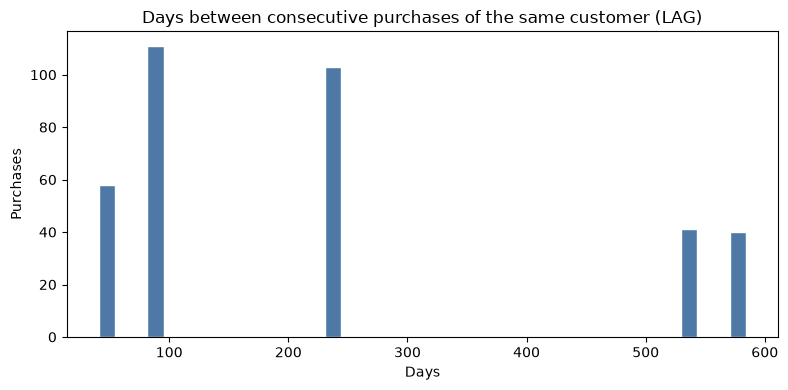

median gap: 233 days


In [7]:
gaps = q("""
SELECT customer_id, invoice_date::date AS invoice_date,
       invoice_date::date - lag(invoice_date::date) OVER (PARTITION BY customer_id ORDER BY invoice_date) AS days_since_prev
FROM invoice
""")
yearly = q("""
WITH y AS (SELECT extract(year FROM invoice_date)::int AS year, sum(total) AS revenue FROM invoice GROUP BY 1)
SELECT year, revenue, round(100 * (revenue / lag(revenue) OVER (ORDER BY year) - 1), 1) AS yoy_growth_pct
FROM y ORDER BY year
""")
print(yearly.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(gaps["days_since_prev"].dropna(), bins=40, color="#4E79A7", edgecolor="white")
ax.set(title="Days between consecutive purchases of the same customer (LAG)", xlabel="Days", ylabel="Purchases")
plt.tight_layout()
plt.show()
print(f"median gap: {gaps['days_since_prev'].median():.0f} days")

The gaps cluster at a few values: the Chinook generator created purchases on a regular schedule. Real customer data shows a much wider, right-skewed distribution. The same query on real data is a first step towards a churn model (M16).

*Insight: When you need a value from "other rows" but want to keep every row (running totals, ranks, previous values, shares of a group), use a window function instead of a self join or a correlated subquery. It is shorter and usually much faster.*

## Real-World Use Case or Analogy

A window function is like **reading a race result table**. For each runner (row), you can see their place (`RANK`), the time gap to the runner in front (`LAG`), and their split times added up so far (running total), without merging all runners into one summary line.

Product analytics depends on window functions: month-over-month growth, cohort retention, sessionisation of click streams, "first purchase per customer", and deduplication with `ROW_NUMBER() ... WHERE rn = 1`.